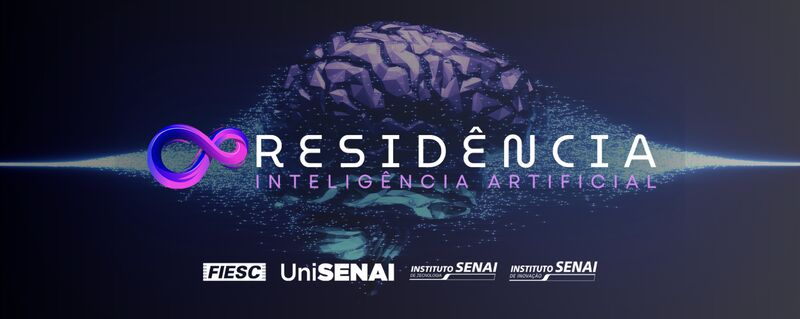

<h1><b>Pós-Graduação em Inteligência Artificial Aplicada</b></h1>



<h2>Unidade Curricular : Aprendizado Profundo</h2>



<h2>Professor : Gincarlo Marchesini</h2>



<h1><b>Desafio Final <b></h1>

---

**Temática**: Transformadores no setor elétrico

**Alunos**: Ana Carolina Dutra Ramos, Camila Gois de Jesus, Guilherme Magalhães Júnior

**Data**: 07/53/2026


---

##inicio EDA

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler,OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
import tensorflow as tf
import random

In [ ]:
# Fixar resultados
tf.random.set_seed(42)
np.random.seed(42)
random.seed(42)

Treino = pd.read_csv('transformers.csv')
Treino

,date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT,class
0,2016-07-03 00:00:00,10.382,5.425,7.604,2.310,2.955,1.675,29.334999,0
1,2016-07-03 01:00:00,9.779,5.224,6.716,2.843,2.650,1.675,26.028000,0
2,2016-07-03 02:00:00,10.382,4.689,7.320,2.203,2.985,1.858,24.340000,0
3,2016-07-03 03:00:00,9.779,4.153,6.823,1.990,2.528,1.675,26.450001,0
4,2016-07-03 04:00:00,10.717,4.756,7.356,2.807,2.650,1.797,25.958000,0
...,...,...,...,...,...,...,...,...,...
17343,2018-06-25 15:00:00,-8.439,3.885,-11.229,2.132,3.107,1.432,11.607000,0
17344,2018-06-25 16:00:00,-1.206,3.215,-4.833,1.635,2.955,1.279,12.381000,0
17345,2018-06-25 17:00:00,4.622,3.081,1.883,1.635,3.655,1.249,11.467000,0
17346,2018-06-25 18:00:00,8.841,3.550,5.366,1.777,3.472,1.310,11.185000,0


In [ ]:
Treino.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17348 entries, 0 to 17347
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   date    17348 non-null  object 
 1   HUFL    17348 non-null  float64
 2   HULL    17348 non-null  float64
 3   MUFL    17348 non-null  float64
 4   MULL    17348 non-null  float64
 5   LUFL    17348 non-null  float64
 6   LULL    17348 non-null  float64
 7   OT      17348 non-null  float64
 8   class   17348 non-null  int64  
dtypes: float64(7), int64(1), object(1)
memory usage: 1.2+ MB


In [ ]:
Treino.isnull().sum()

,0
date,0
HUFL,0
HULL,0
MUFL,0
MULL,0
LUFL,0
LULL,0
OT,0
class,0


In [ ]:
Treino.describe()

,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT,class
count,17348.000000,17348.000000,17348.000000,17348.000000,17348.000000,17348.000000,17348.000000,17348.000000
mean,7.378466,2.235379,4.305553,0.877379,3.064325,0.854008,13.306938,0.009972
std,7.071374,2.042030,6.830529,1.810825,1.164918,0.598867,8.571117,0.099365
min,-22.705999,-4.756000,-25.087999,-5.934000,-1.188000,-1.371000,-4.080000,0.000000
25%,5.827000,0.737000,3.305000,-0.320000,2.284000,0.670000,6.964000,0.000000
50%,8.774000,2.210000,5.970000,0.924000,2.833000,0.975000,11.396000,0.000000
75%,11.788000,3.684000,8.635000,2.203000,3.625000,1.218000,18.009001,0.000000
max,23.643999,10.114000,17.341000,7.747000,8.498000,3.046000,46.007000,1.000000


In [ ]:
print(f"Linhas duplicadas: {Treino.duplicated().sum()}")

print(f"datas únicas: {Treino['date'].nunique()} em {len(Treino)} linhas")

Linhas duplicadas: 0
datas únicas: 17348 em 17348 linhas


In [ ]:
Treino['class'].value_counts()

,count
class,
0,17175
1,173


In [ ]:
Treino['date'] = pd.to_datetime(Treino['date'])
Treino = Treino.set_index('date')

In [ ]:
Treino

,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT,class
date,,,,,,,,
2016-07-03 00:00:00,10.382,5.425,7.604,2.310,2.955,1.675,29.334999,0
2016-07-03 01:00:00,9.779,5.224,6.716,2.843,2.650,1.675,26.028000,0
2016-07-03 02:00:00,10.382,4.689,7.320,2.203,2.985,1.858,24.340000,0
2016-07-03 03:00:00,9.779,4.153,6.823,1.990,2.528,1.675,26.450001,0
2016-07-03 04:00:00,10.717,4.756,7.356,2.807,2.650,1.797,25.958000,0
...,...,...,...,...,...,...,...,...
2018-06-25 15:00:00,-8.439,3.885,-11.229,2.132,3.107,1.432,11.607000,0
2018-06-25 16:00:00,-1.206,3.215,-4.833,1.635,2.955,1.279,12.381000,0
2018-06-25 17:00:00,4.622,3.081,1.883,1.635,3.655,1.249,11.467000,0


<Figure size 1200x800 with 0 Axes>

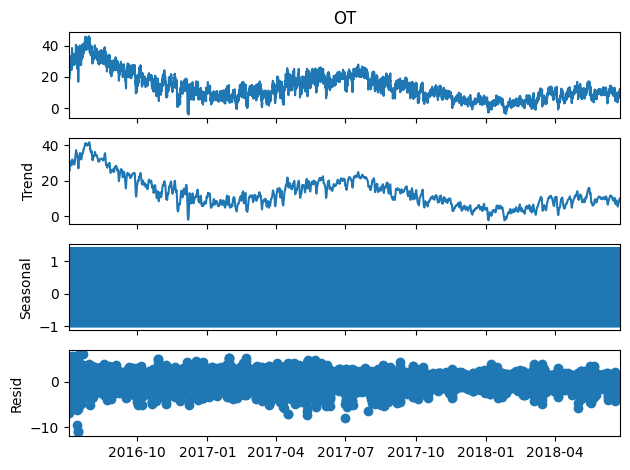

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Analisando a sazonalidade da Temperatura do Óleo (OT)
Comp = seasonal_decompose(Treino['OT'], model='additive', period=24)

plt.figure(figsize=(12, 8))
Comp.plot()
plt.show()

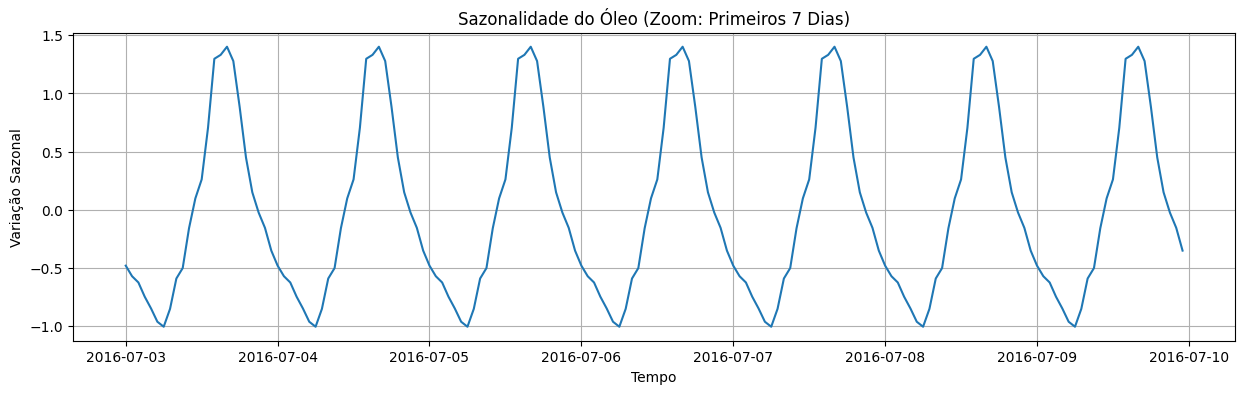

In [ ]:
# Fazendo a decomposição
res = seasonal_decompose(Treino['OT'], model='additive', period=24)

# Criando um gráfico apenas dos primeiros 7 dias
plt.figure(figsize=(15, 4))
plt.plot(res.seasonal[:168]) # Pega por horas
plt.title("Sazonalidade do Óleo (Zoom: Primeiros 7 Dias)")
plt.xlabel("Tempo")
plt.ylabel("Variação Sazonal")
plt.grid(True)
plt.show()

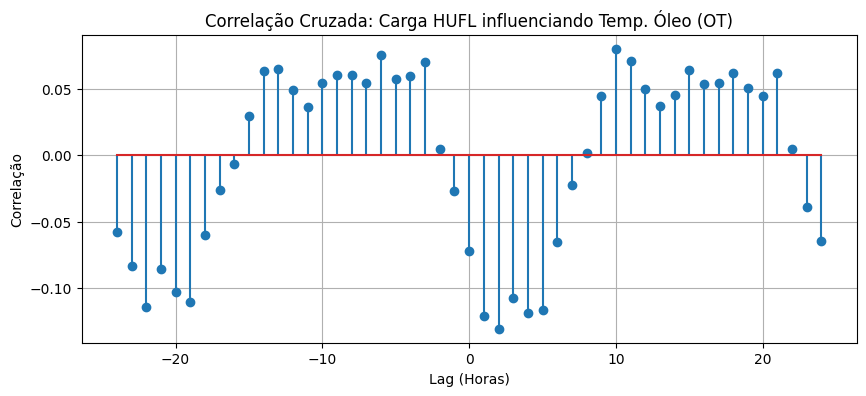

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf

# Diferenciação
ot_diff = Treino['OT'].diff().dropna()
hufl_diff = Treino['HUFL'].diff().dropna()

# Função de Correlação Cruzada
def plot_cross_corr(x, y, label_x, label_y, max_lag=24):
    lags = np.arange(-max_lag, max_lag + 1)
    corr = [x.shift(l).corr(y) for l in lags]
    plt.figure(figsize=(10, 4))
    plt.stem(lags, corr)
    plt.title(f"Correlação Cruzada: {label_x} influenciando {label_y}")
    plt.xlabel("Lag (Horas)")
    plt.ylabel("Correlação")
    plt.grid(True)
    plt.show()
plot_cross_corr(hufl_diff, ot_diff, "Carga HUFL", "Temp. Óleo (OT)")

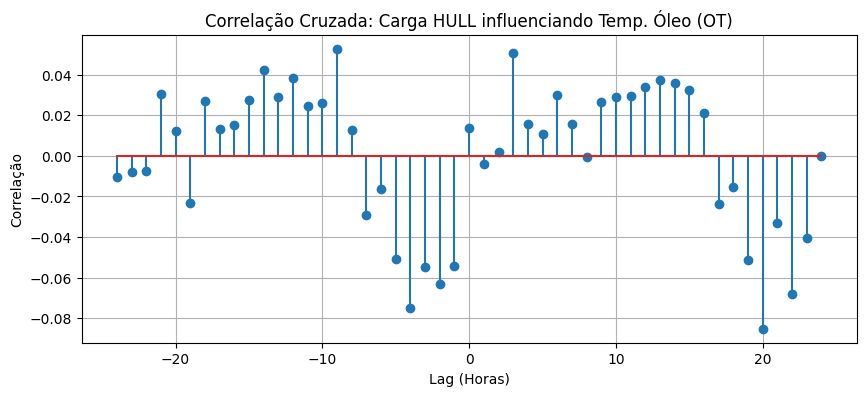

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf

# Diferenciação
ot_diff = Treino['OT'].diff().dropna()
hull_diff = Treino['HULL'].diff().dropna()

#  Função de Correlação Cruzada
def plot_cross_corr(x, y, label_x, label_y, max_lag=24):
    lags = np.arange(-max_lag, max_lag + 1)
    corr = [x.shift(l).corr(y) for l in lags]
    plt.figure(figsize=(10, 4))
    plt.stem(lags, corr)
    plt.title(f"Correlação Cruzada: {label_x} influenciando {label_y}")
    plt.xlabel("Lag (Horas)")
    plt.ylabel("Correlação")
    plt.grid(True)
    plt.show()
plot_cross_corr(hull_diff, ot_diff, "Carga HULL", "Temp. Óleo (OT)")

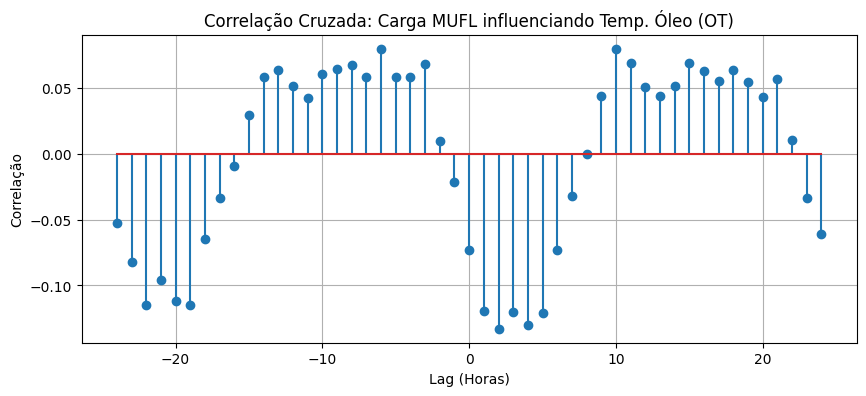

In [ ]:

from statsmodels.graphics.tsaplots import plot_acf

# Diferenciação
ot_diff = Treino['OT'].diff().dropna()
mufl_diff = Treino['MUFL'].diff().dropna()
def plot_cross_corr(x, y, label_x, label_y, max_lag=24):
    lags = np.arange(-max_lag, max_lag + 1)
    corr = [x.shift(l).corr(y) for l in lags]
    plt.figure(figsize=(10, 4))
    plt.stem(lags, corr)
    plt.title(f"Correlação Cruzada: {label_x} influenciando {label_y}")
    plt.xlabel("Lag (Horas)")
    plt.ylabel("Correlação")
    plt.grid(True)
    plt.show()
plot_cross_corr(mufl_diff, ot_diff, "Carga MUFL", "Temp. Óleo (OT)")

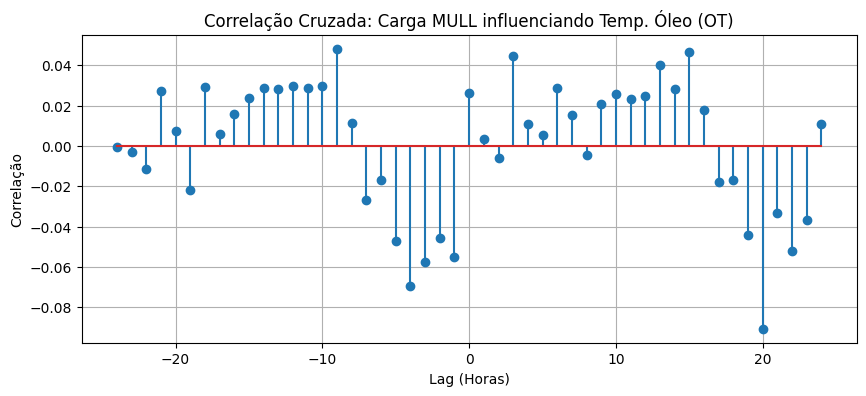

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf

# Diferenciação
ot_diff = Treino['OT'].diff().dropna()
mull_diff = Treino['MULL'].diff().dropna()

# Função de Correlação Cruzada
def plot_cross_corr(x, y, label_x, label_y, max_lag=24):
    lags = np.arange(-max_lag, max_lag + 1)
    corr = [x.shift(l).corr(y) for l in lags]

    plt.figure(figsize=(10, 4))
    plt.stem(lags, corr)
    plt.title(f"Correlação Cruzada: {label_x} influenciando {label_y}")
    plt.xlabel("Lag (Horas)")
    plt.ylabel("Correlação")
    plt.grid(True)
    plt.show()

plot_cross_corr(mull_diff, ot_diff, "Carga MULL", "Temp. Óleo (OT)")

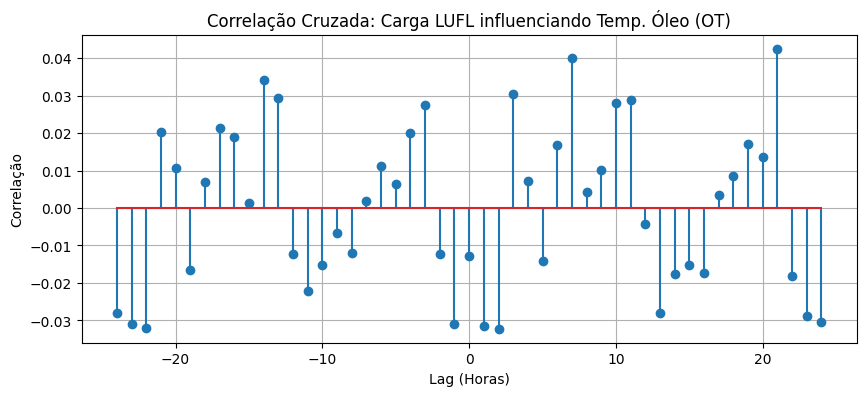

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf

# Diferenciação para limpar as séries
ot_diff = Treino['OT'].diff().dropna()
lufl_diff = Treino['LUFL'].diff().dropna()

# Função de Correlação Cruzada
def plot_cross_corr(x, y, label_x, label_y, max_lag=24):
    lags = np.arange(-max_lag, max_lag + 1)
    corr = [x.shift(l).corr(y) for l in lags]

    plt.figure(figsize=(10, 4))
    plt.stem(lags, corr)
    plt.title(f"Correlação Cruzada: {label_x} influenciando {label_y}")
    plt.xlabel("Lag (Horas)")
    plt.ylabel("Correlação")
    plt.grid(True)
    plt.show()
plot_cross_corr(lufl_diff, ot_diff, "Carga LUFL", "Temp. Óleo (OT)")

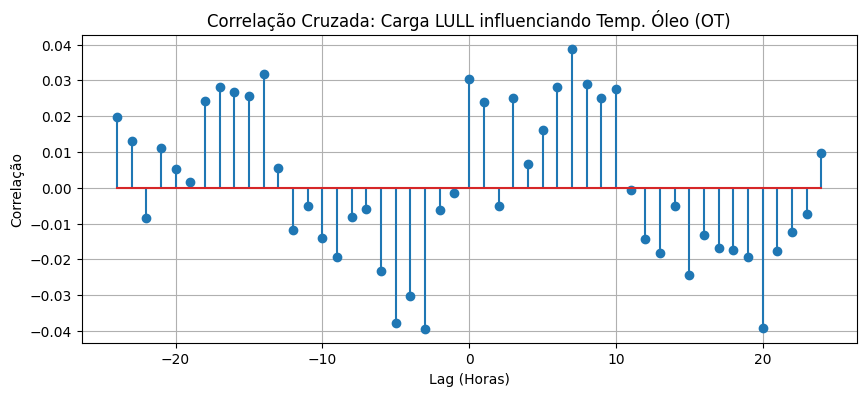

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf

# Diferenciação para limpar as séries
ot_diff = Treino['OT'].diff().dropna()
lull_diff = Treino['LULL'].diff().dropna()

# Função de Correlação Cruzada
def plot_cross_corr(x, y, label_x, label_y, max_lag=24):
    lags = np.arange(-max_lag, max_lag + 1)
    corr = [x.shift(l).corr(y) for l in lags]

    plt.figure(figsize=(10, 4))
    plt.stem(lags, corr)
    plt.title(f"Correlação Cruzada: {label_x} influenciando {label_y}")
    plt.xlabel("Lag (Horas)")
    plt.ylabel("Correlação")
    plt.grid(True)
    plt.show()
plot_cross_corr(lull_diff, ot_diff, "Carga LULL", "Temp. Óleo (OT)")

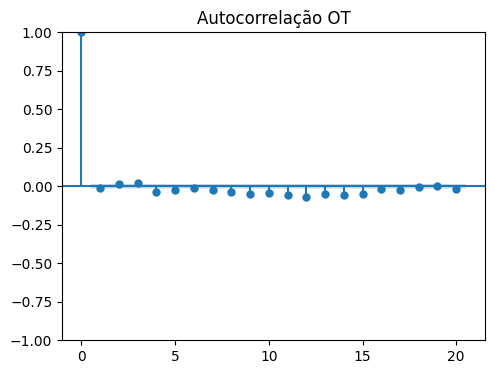

In [ ]:
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plot_acf(ot_diff, ax=plt.gca(), lags=20)
plt.title("Autocorrelação OT")
plt.show()


#AUTOENCODER

In [ ]:
#Feature testes
def apply_feature_engineering(df_input):
    df = df_input.copy()

    #  Converter data e extrair características
    df['date'] = pd.to_datetime(df['date'])
    df['hour'] = df['date'].dt.hour
    df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24)
    df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24)

    #  Lags (1 e 2 pra teste)
    for col in ['OT', 'HUFL', 'MUFL', 'LUFL']:
        df[f'{col}_lag1'] = df[col].shift(1)
        df[f'{col}_lag2'] = df[col].shift(2)

    #  Médias Móveis e Volatilidade (Janela de 3)
    df['OT_rolling_mean'] = df['OT'].rolling(window=3).mean()
    df['OT_rolling_std'] = df['OT'].rolling(window=3).std()

    #  Diferenciação (Velocidade de mudança)
    df['delta_OT'] = df['OT'].diff()
    df['delta_HUFL'] = df['HUFL'].diff()

    # Relação Física (Eficiência Térmica) carga em oposição a temp
    df['load_total'] = df['HUFL'] + df['MUFL'] + df['LUFL']
    df['temp_per_load'] = df['OT'] / (df['load_total'] + 1e-5)

    # "Remover linhas com NaN" (não tem, mas tô deixaido de garantia mesm)
    df = df.dropna().reset_index(drop=True)

    # Definir as novas colunas de features (sem data e class)
    exclude = ['date', 'class', 'hour', 'reconstruction_error', 'is_anomaly', 'anomaly_ae']
    new_features = [c for c in df.columns if c not in exclude]

    return df, new_features


Com Isolation

Epoch 1/200
340/340 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - loss: 0.0289 - val_loss: 0.0241
Epoch 2/200
340/340 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0140 - val_loss: 0.0154
Epoch 3/200
340/340 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0100 - val_loss: 0.0118
Epoch 4/200
340/340 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0082 - val_loss: 0.0102
Epoch 5/200
340/340 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0075 - val_loss: 0.0093
Epoch 6/200
340/340 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0072 - val_loss: 0.0089
Epoch 7/200
340/340 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0069 - val_loss: 0.0088
Epoch 8/200
340/340 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0067 - val_loss: 0.0088
Epoch 9/200
340/340 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0063 - val_loss: 0.0088
Epoch 10/200
340/340 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0059 - val_loss: 0.0082
Epoch 11/200
340/340 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0056 - val_loss: 0.0079
Epoch 12/200
340/340 ━━━━━━━━━━━━━━━━━━━━

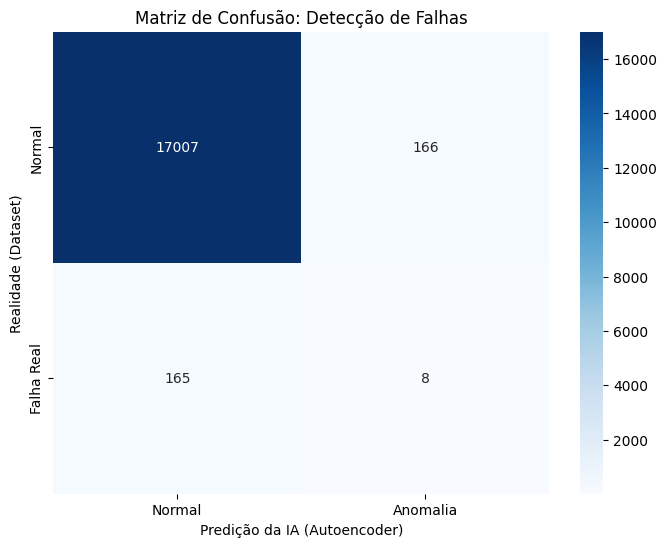

              precision    recall  f1-score   support

      Normal       0.99      0.99      0.99     17173
  Falha Real       0.05      0.05      0.05       173

    accuracy                           0.98     17346
   macro avg       0.52      0.52      0.52     17346
weighted avg       0.98      0.98      0.98     17346



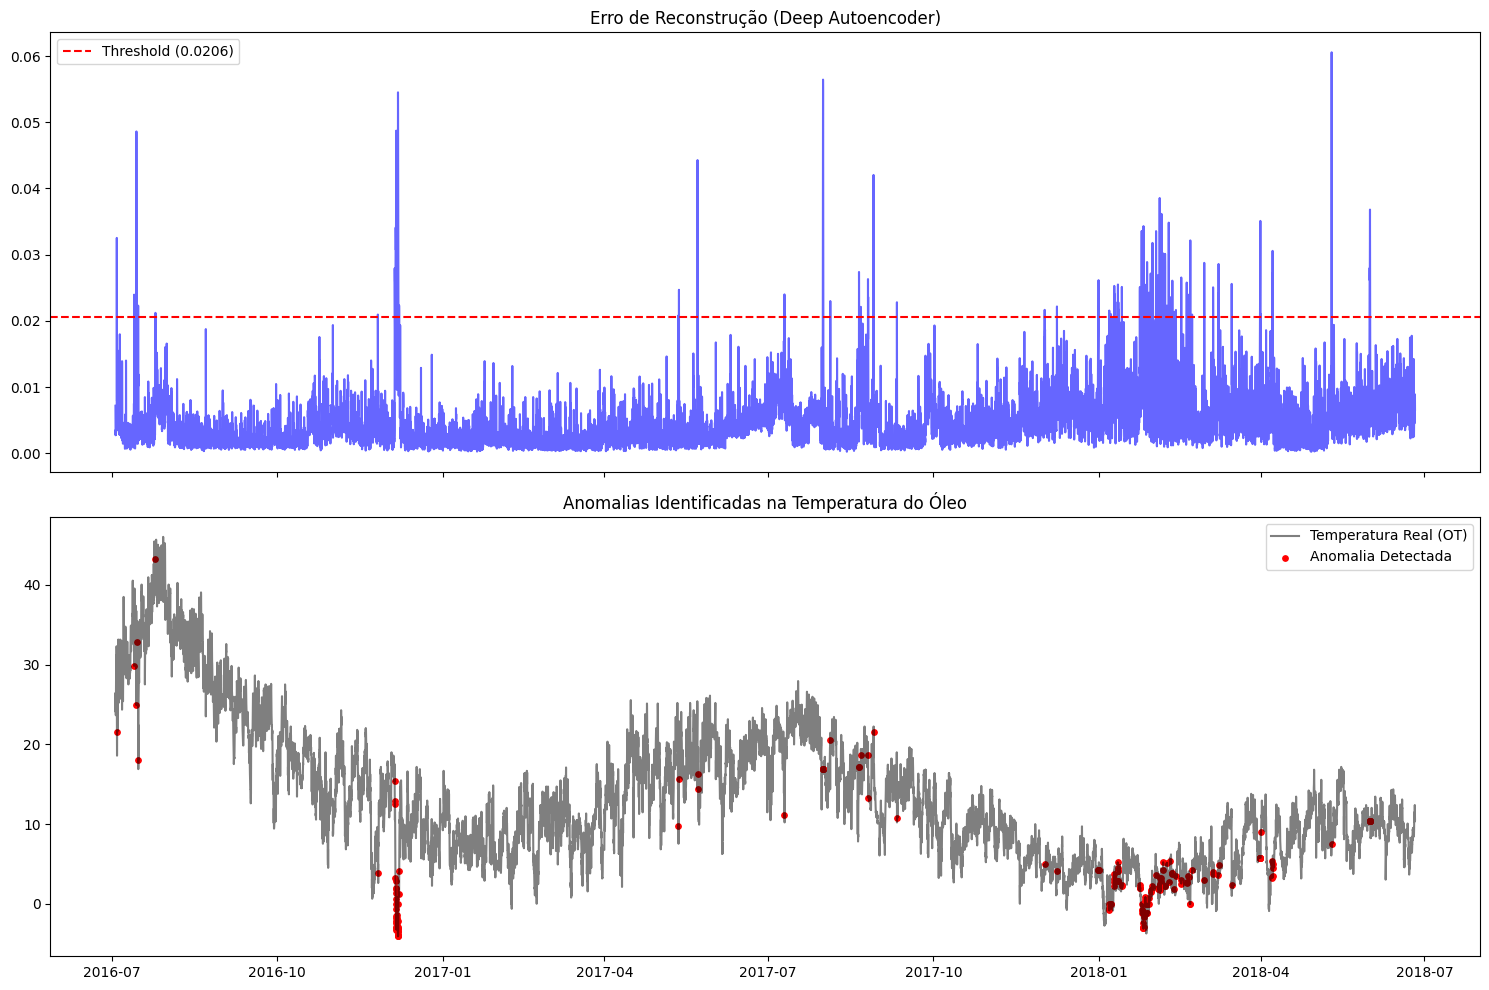

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import IsolationForest
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.initializers import HeNormal, GlorotUniform

df = pd.read_csv('transformers.csv')
df, features_expandidas = apply_feature_engineering(df)
# 1. Preparar os dados
df_normal = df[df['class'] == 0]
split_idx = int(0.8 * len(df_normal))
df_normal = df_normal.iloc[:split_idx].copy() #separar aqui pra reino
X_bruto = df_normal[features_expandidas].values

# Limpeza prévia com Isolation Forest
iso = IsolationForest(contamination=0.01, random_state=42)
outliers = iso.fit_predict(X_bruto)
X_limpo = X_bruto[outliers == 1]

# Normalização
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_limpo)
X_full_scaled = scaler.transform(df[features_expandidas].values)

# Deep Autoencoder
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

autoencoder = models.Sequential([
    layers.Input(shape=(len(features_expandidas),)),

    layers.Dense(16, activation='relu', kernel_initializer=HeNormal()),
    layers.BatchNormalization(),
    layers.Dense(8, activation='relu'),
    layers.Dense(4, activation='relu'),

    layers.Dense(8, activation='relu'),
    layers.BatchNormalization(),
    layers.Dense(16, activation='relu'),
    layers.Dense(len(features_expandidas), activation='sigmoid', kernel_initializer=GlorotUniform())
])

autoencoder.compile(optimizer='adam', loss='mse')

# Treino com Early Stopping
history = autoencoder.fit(
    X_train_scaled, X_train_scaled,
    epochs=200,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

X_pred = autoencoder.predict(X_full_scaled)
mse = np.mean(np.power(X_full_scaled - X_pred, 2), axis=1)

# Definindo o threshold
threshold = np.percentile(mse, 99)
df['reconstruction_error'] = mse
df['is_anomaly'] = df['reconstruction_error'] > threshold

#plots
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
y_true = df['class']
y_pred = df['is_anomaly'].astype(int)

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal', 'Anomalia'],
            yticklabels=['Normal', 'Falha Real'])
plt.xlabel('Predição da IA (Autoencoder)')
plt.ylabel('Realidade (Dataset)')
plt.title('Matriz de Confusão: Detecção de Falhas')
plt.show()

print(classification_report(y_true, y_pred, target_names=['Normal', 'Falha Real']))

eixo_x = df['date'] if 'date' in df.columns else df.index

fig, ax = plt.subplots(2, 1, figsize=(15, 10), sharex=True)

ax[0].plot(eixo_x, df['reconstruction_error'], color='blue', alpha=0.6)
ax[0].axhline(y=threshold, color='red', linestyle='--', label=f'Threshold ({threshold:.4f})')
ax[0].set_title("Erro de Reconstrução (Deep Autoencoder)")
ax[0].legend()


ax[1].plot(eixo_x, df['OT'], color='black', alpha=0.5, label='Temperatura Real (OT)')
anomalias = df[df['is_anomaly']]
ax[1].scatter(anomalias['date'] if 'date' in df.columns else anomalias.index,
            anomalias['OT'], color='red', s=15, label='Anomalia Detectada')
ax[1].set_title("Anomalias Identificadas na Temperatura do Óleo")
ax[1].legend()

plt.tight_layout()
plt.show()

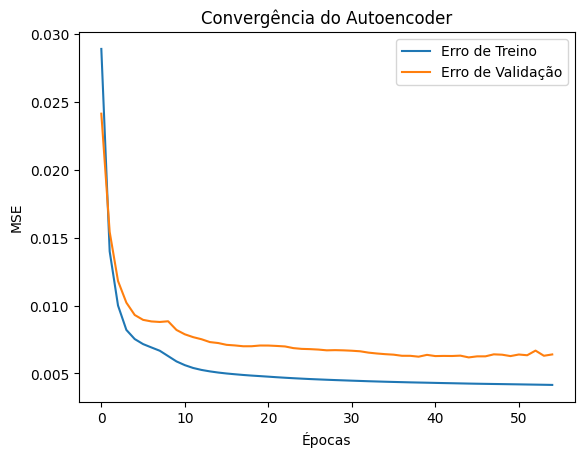

In [ ]:
plt.plot(history.history['loss'], label='Erro de Treino')
plt.plot(history.history['val_loss'], label='Erro de Validação')
plt.title('Convergência do Autoencoder')
plt.xlabel('Épocas')
plt.ylabel('MSE')
plt.legend()
plt.show()

In [ ]:
# Análise extra

df_anomalias = df[df['is_anomaly'] == True]
falhas_reais = df[df['class'] == 1]

acertos_ia = df[(df['class'] == 1) & (df['is_anomaly'] == True)]

dados_normais_puros = df[(df['class'] == 0) & (df['is_anomaly'] == False)]

print("-" * 50)
print("ESTATÍSTICAS DE TEMPERATURA (OT)")
print(f"Média OT (Dados Normais): {dados_normais_puros['OT'].mean():.2f}°C")
print(f"Média OT (Anomalias IA):  {df_anomalias['OT'].mean():.2f}°C")
print("-" * 50)

print("ANÁLISE DE DESEMPENHO (VALIDAÇÃO)")
print(f"Total de falhas reais no CSV (Class 1): {len(falhas_reais)}")
print(f"Total de anomalias que a IA detectou:  {len(df_anomalias)}")
print(f"Falhas Reais capturadas pela IA:       {len(acertos_ia)}")

if len(falhas_reais) > 0:
    recall = (len(acertos_ia) / len(falhas_reais)) * 100
    print(f"Taxa de acerto das falhas (Recall):    {recall:.2f}%")

print("\n--- MÉDIAS DE ERRO DE RECONSTRUÇÃO ---")
print(f"Erro Médio - Dados Normais: {dados_normais_puros['reconstruction_error'].mean():.6f}")
print(f"Erro Médio - Falhas Reais:  {falhas_reais['reconstruction_error'].mean():.6f}")
print(f"Threshold utilizado:        {threshold:.6f}")
print("-" * 50)

print("\nAMOSTRA DAS ANOMALIAS DETECTADAS (TOP 10):")
print(df_anomalias[['date', 'HUFL', 'OT', 'reconstruction_error', 'class']].head(10))

--------------------------------------------------
ESTATÍSTICAS DE TEMPERATURA (OT)
Média OT (Dados Normais): 13.46°C
Média OT (Anomalias IA):  4.69°C
--------------------------------------------------
ANÁLISE DE DESEMPENHO (VALIDAÇÃO)
Total de falhas reais no CSV (Class 1): 173
Total de anomalias que a IA detectou:  174
Falhas Reais capturadas pela IA:       8
Taxa de acerto das falhas (Recall):    4.62%

--- MÉDIAS DE ERRO DE RECONSTRUÇÃO ---
Erro Médio - Dados Normais: 0.004214
Erro Médio - Falhas Reais:  0.008174
Threshold utilizado:        0.020630
--------------------------------------------------

AMOSTRA DAS ANOMALIAS DETECTADAS (TOP 10):
                    date    HUFL         OT  reconstruction_error  class
18   2016-07-03 20:00:00  11.186  21.525999              0.032525      0
249  2016-07-13 11:00:00   8.573  29.827000              0.023955      0
280  2016-07-14 18:00:00   6.430  24.903000              0.048608      0
281  2016-07-14 19:00:00   7.837  32.852001          

#LSTM

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, average_precision_score, roc_auc_score, f1_score, recall_score, precision_score, mean_absolute_error, mean_squared_error
from sklearn.utils.class_weight import compute_class_weight

In [ ]:
# Preparando o dataset

ds_lstm = pd.read_csv('transformers.csv')

ds_lstm['date'] = pd.to_datetime(ds_lstm['date'])
ds_lstm = ds_lstm.sort_values('date').reset_index(drop=True)

In [ ]:
features = ds_lstm.drop(columns=['date', 'class']).columns.tolist()

features

['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']

In [ ]:
# Separando dados e rótulo

X = ds_lstm[features]
y = ds_lstm[['OT']]
dates = ds_lstm['date']

In [ ]:
# Split

idx_split = int(len(ds_lstm) * 0.8)

X_train_lstm = X.iloc[:idx_split].copy()
X_test_lstm = X.iloc[idx_split:].copy()

y_train_lstm = y.iloc[:idx_split].copy()
y_test_lstm = y.iloc[idx_split:].copy()

dates_train = dates.iloc[:idx_split].copy()
dates_test = dates.iloc[idx_split:].copy()

In [ ]:
# Padronização dos dados

scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train_lstm)
X_test_scaled = scaler_X.transform(X_test_lstm)

y_train_scaled = scaler_y.fit_transform(y_train_lstm).ravel()
y_test_scaled = scaler_y.transform(y_test_lstm).ravel()

In [ ]:
# Janelas deslizantes

def criar_janelas_lstm(X_array, y_array, datas, lookback=24, horizon=4):
    X_seq = []
    y_seq = []
    datas_seq = []

    for i in range(lookback, len(X_array) - horizon + 1):
        X_seq.append(X_array[i-lookback:i, :])
        y_seq.append(y_array[i:i+horizon])
        datas_seq.append(datas.iloc[i:i+horizon].values)

    return np.array(X_seq), np.array(y_seq), np.array(datas_seq)

In [ ]:
lookback = 24
horizon = 4

X_train_seq, y_train_seq, dates_train_seq = criar_janelas_lstm(
    X_train_scaled,
    y_train_scaled,
    dates_train,
    lookback=lookback,
    horizon=horizon
)

X_test_seq, y_test_seq, dates_test_seq = criar_janelas_lstm(
    X_test_scaled,
    y_test_scaled,
    dates_test,
    lookback=lookback,
    horizon=horizon
)

print("X_train_seq:", X_train_seq.shape)
print("y_train_seq:", y_train_seq.shape)
print("X_test_seq:", X_test_seq.shape)
print("y_test_seq:", y_test_seq.shape)

X_train_seq: (13851, 24, 7)
y_train_seq: (13851, 4)
X_test_seq: (3443, 24, 7)
y_test_seq: (3443, 4)


In [ ]:
# LSTM

n_timesteps = X_train_seq.shape[1]
n_features = X_train_seq.shape[2]

input_layer = layers.Input(shape=(n_timesteps, n_features))

x = layers.LSTM(64, return_sequences=False)(input_layer)
x = layers.Dropout(0.2)(x)
x = layers.Dense(32, activation='relu')(x)

output_layer = layers.Dense(horizon, activation='linear')(x)

model_lstm = Model(inputs=input_layer, outputs=output_layer)

model_lstm.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

model_lstm.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 24, 7)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,644 (80.64 KB)

 Trainable params: 20,644 (80.64 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Treinando modelo

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history_lstm = model_lstm.fit(
    X_train_seq,
    y_train_seq,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    shuffle=False,
    callbacks=[early_stop],
    verbose=0
)

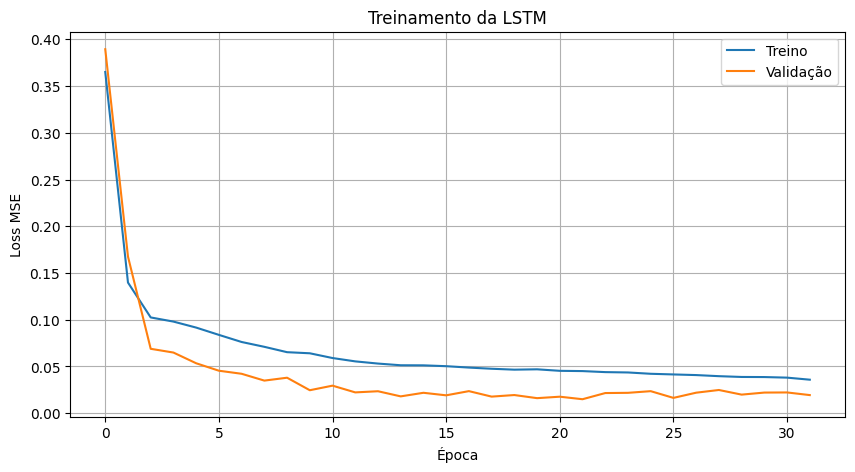

In [ ]:
# Gráfico de treino

plt.figure(figsize=(10, 5))

plt.plot(history_lstm.history['loss'], label='Treino')
plt.plot(history_lstm.history['val_loss'], label='Validação')

plt.xlabel('Época')
plt.ylabel('Loss MSE')
plt.title('Treinamento da LSTM')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Predição

y_pred_scaled = model_lstm.predict(X_test_seq)

108/108 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step


In [ ]:
y_pred = scaler_y.inverse_transform(
    y_pred_scaled.reshape(-1, 1)
).reshape(y_pred_scaled.shape)

y_test_real = scaler_y.inverse_transform(
    y_test_seq.reshape(-1, 1)
).reshape(y_test_seq.shape)

In [ ]:
# Avaliando erro para cada horizonte

for h in range(horizon):
    mae = mean_absolute_error(y_test_real[:, h], y_pred[:, h])
    rmse = np.sqrt(mean_squared_error(y_test_real[:, h], y_pred[:, h]))

    print(f'Horizonte t+{h+1}: MAE = {mae:.4f} | RMSE = {rmse:.4f}')

Horizonte t+1: MAE = 0.5681 | RMSE = 0.7631
Horizonte t+2: MAE = 0.7407 | RMSE = 1.0015
Horizonte t+3: MAE = 0.8615 | RMSE = 1.1679
Horizonte t+4: MAE = 0.9724 | RMSE = 1.3193


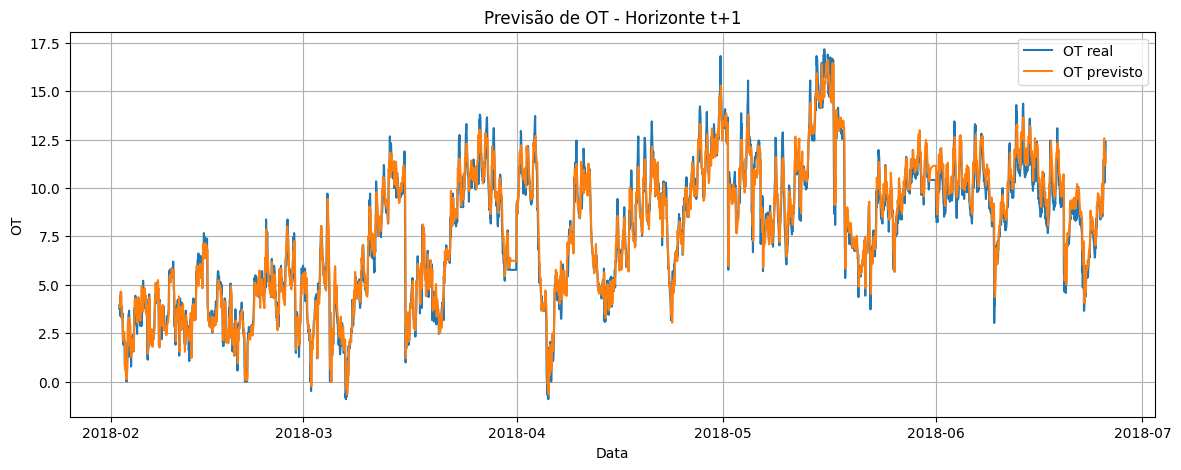

In [ ]:
# Gráfico: real x previsto

h = 0

plt.figure(figsize=(14, 5))

plt.plot(
    dates_test_seq[:, h],
    y_test_real[:, h],
    label='OT real'
)

plt.plot(
    dates_test_seq[:, h],
    y_pred[:, h],
    label='OT previsto'
)

plt.xlabel('Data')
plt.ylabel('OT')
plt.title('Previsão de OT - Horizonte t+1')
plt.legend()
plt.grid(True)
plt.show()

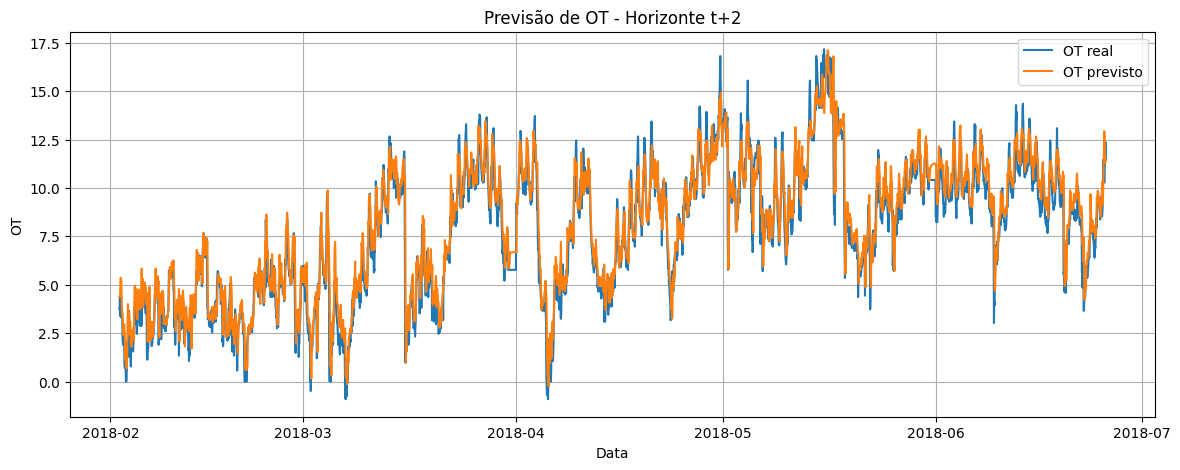

In [ ]:
h = 1

plt.figure(figsize=(14, 5))

plt.plot(
    dates_test_seq[:, h],
    y_test_real[:, h],
    label='OT real'
)

plt.plot(
    dates_test_seq[:, h],
    y_pred[:, h],
    label='OT previsto'
)

plt.xlabel('Data')
plt.ylabel('OT')
plt.title('Previsão de OT - Horizonte t+2')
plt.legend()
plt.grid(True)
plt.show()

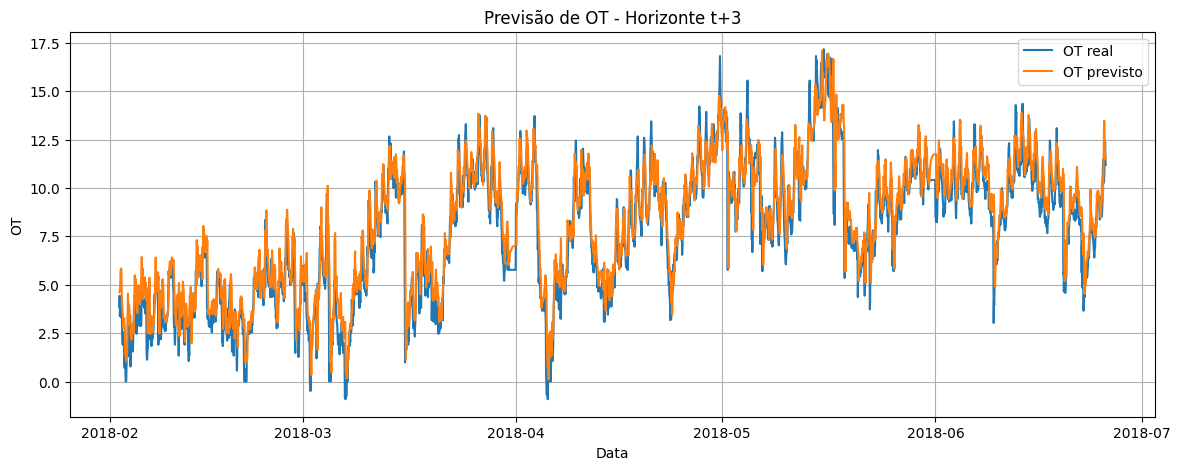

In [ ]:
h = 2

plt.figure(figsize=(14, 5))

plt.plot(
    dates_test_seq[:, h],
    y_test_real[:, h],
    label='OT real'
)

plt.plot(
    dates_test_seq[:, h],
    y_pred[:, h],
    label='OT previsto'
)

plt.xlabel('Data')
plt.ylabel('OT')
plt.title('Previsão de OT - Horizonte t+3')
plt.legend()
plt.grid(True)
plt.show()

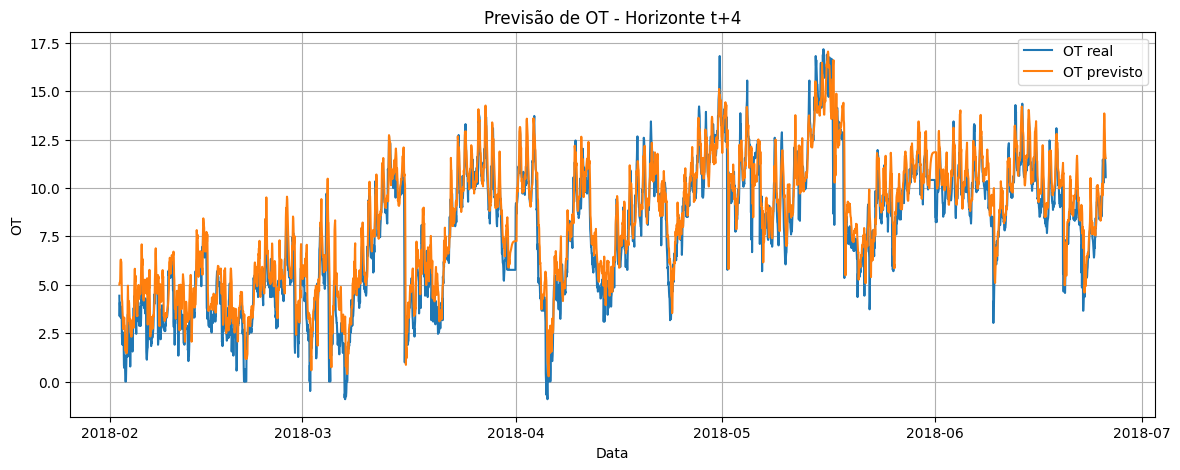

In [ ]:
h = 3

plt.figure(figsize=(14, 5))

plt.plot(
    dates_test_seq[:, h],
    y_test_real[:, h],
    label='OT real'
)

plt.plot(
    dates_test_seq[:, h],
    y_pred[:, h],
    label='OT previsto'
)

plt.xlabel('Data')
plt.ylabel('OT')
plt.title('Previsão de OT - Horizonte t+4')
plt.legend()
plt.grid(True)
plt.show()

#MLP

In [ ]:
# Preparando o dataset


ds_classif = pd.read_csv('transformers.csv')

ds_classif['date'] = pd.to_datetime(ds_classif['date'])
ds_classif = ds_classif.sort_values('date').reset_index(drop=True)

X = ds_classif.drop(columns=['date', 'class'])
y = ds_classif['class']

In [ ]:
# Split

idx_split = int(len(ds_classif) * 0.8)

X_train = X.iloc[:idx_split].copy()
X_test = X.iloc[idx_split:].copy()

y_train = y.iloc[:idx_split].copy()
y_test = y.iloc[idx_split:].copy()

In [ ]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\ny_train:")
print(y_train.value_counts(normalize=True))

print("\ny_test:")
print(y_test.value_counts(normalize=True))

X_train: (13878, 7)
X_test: (3470, 7)

y_train:
class
0    0.994956
1    0.005044
Name: proportion, dtype: float64

y_test:
class
0    0.970317
1    0.029683
Name: proportion, dtype: float64


In [ ]:
# Padronização dos dados

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
# Feature engineering

classes = np.unique(y_train)

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)

class_weights_dict = dict(zip(classes, class_weights))

class_weights_dict

{np.int64(0): np.float64(0.5025347624565469),
 np.int64(1): np.float64(99.12857142857143)}

## Testando arquiteturas diferentes

### Teste arquitetura 1

In [ ]:
# Definindo o modelo

n_features = X_train_scaled.shape[1]

input_layer = layers.Input(shape=(n_features,))

x = layers.Dense(64, activation='relu')(input_layer)
x = layers.Dropout(0.3)(x)

x = layers.Dense(32, activation='relu')(x)
x = layers.Dropout(0.3)(x)

x = layers.Dense(16, activation='relu')(x)

output_layer = layers.Dense(1, activation='sigmoid')(x)

model_mlp = Model(inputs=input_layer, outputs=output_layer)

model_mlp.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall')
    ]
)

model_mlp.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 7)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,137 (12.25 KB)

 Trainable params: 3,137 (12.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Treinando o modelo

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history_mlp = model_mlp.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    shuffle=False,
    class_weight=class_weights_dict,
    callbacks=[early_stop],
    verbose=0
)

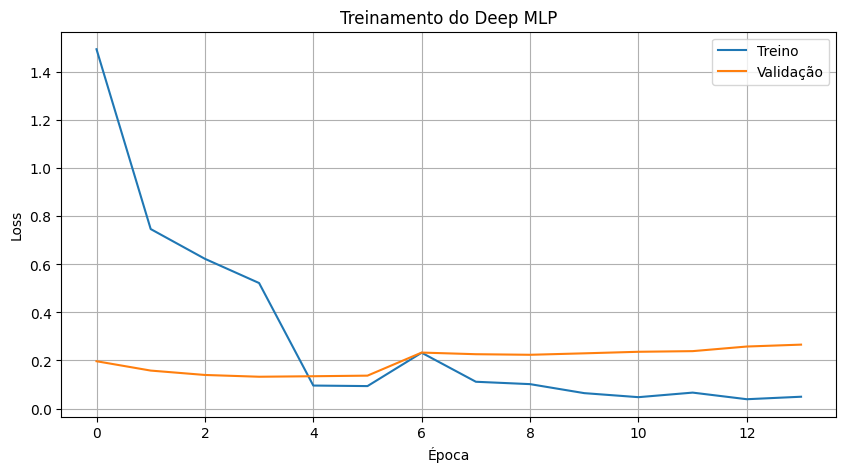

In [ ]:
# Gráfico de avaliação do treinamento

plt.figure(figsize=(10, 5))

plt.plot(history_mlp.history['loss'], label='Treino')
plt.plot(history_mlp.history['val_loss'], label='Validação')

plt.xlabel('Época')
plt.ylabel('Loss')
plt.title('Treinamento do Deep MLP')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Predição com os dados de teste

y_proba = model_mlp.predict(X_test_scaled).ravel()
y_pred = (y_proba >= 0.5).astype(int)

109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


In [ ]:
print(confusion_matrix(y_test, y_pred))

print(classification_report(y_test, y_pred, zero_division=0))

[[3367    0]
 [ 103    0]]
              precision    recall  f1-score   support

           0       0.97      1.00      0.98      3367
           1       0.00      0.00      0.00       103

    accuracy                           0.97      3470
   macro avg       0.49      0.50      0.49      3470
weighted avg       0.94      0.97      0.96      3470



In [ ]:
pr_auc = average_precision_score(y_test, y_proba)
roc_auc = roc_auc_score(y_test, y_proba)

print("PR-AUC:", pr_auc)
print("ROC-AUC:", roc_auc)

PR-AUC: 0.049547152019425236
ROC-AUC: 0.5943466137640895


### Teste arquitetura 2

In [ ]:
# Definindo o modelo

n_features = X_train_scaled.shape[1]

input_layer = layers.Input(shape=(n_features,))

x = layers.Dense(128, activation='relu')(input_layer)
x = layers.Dense(64, activation='relu')(x)
x = layers.Dropout(0.3)(x)

x = layers.Dense(32, activation='relu')(x)
x = layers.Dropout(0.3)(x)

x = layers.Dense(16, activation='relu')(x)

output_layer = layers.Dense(1, activation='sigmoid')(x)

model_mlp = Model(inputs=input_layer, outputs=output_layer)

model_mlp.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall')
    ]
)

In [ ]:
# Treinando o modelo

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history_mlp = model_mlp.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    shuffle=False,
    class_weight=class_weights_dict,
    callbacks=[early_stop],
    verbose=0
)

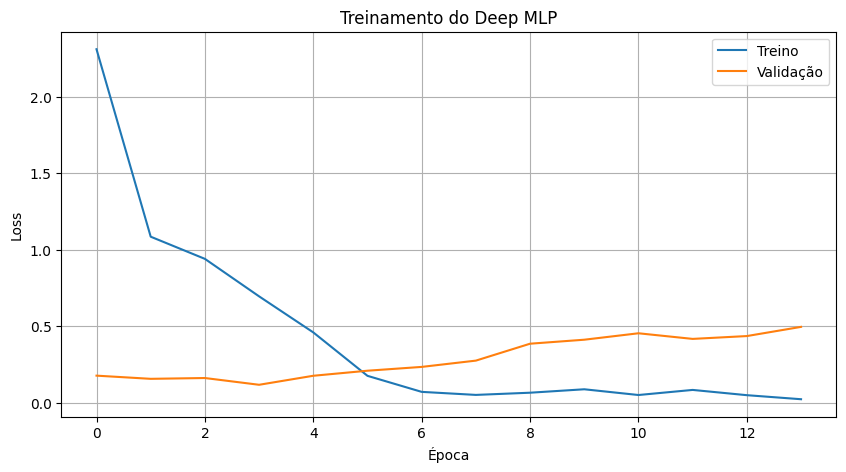

In [ ]:
# Gráfico de avaliação do treinamento

plt.figure(figsize=(10, 5))

plt.plot(history_mlp.history['loss'], label='Treino')
plt.plot(history_mlp.history['val_loss'], label='Validação')

plt.xlabel('Época')
plt.ylabel('Loss')
plt.title('Treinamento do Deep MLP')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Predição com os dados de teste

y_proba = model_mlp.predict(X_test_scaled).ravel()
y_pred = (y_proba >= 0.5).astype(int)

109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


In [ ]:
print(confusion_matrix(y_test, y_pred))

print(classification_report(y_test, y_pred, zero_division=0))

[[3367    0]
 [ 103    0]]
              precision    recall  f1-score   support

           0       0.97      1.00      0.98      3367
           1       0.00      0.00      0.00       103

    accuracy                           0.97      3470
   macro avg       0.49      0.50      0.49      3470
weighted avg       0.94      0.97      0.96      3470



### Teste arquitetura 3

In [ ]:
# Definindo o modelo

n_features = X_train_scaled.shape[1]

input_layer = layers.Input(shape=(n_features,))

x = layers.Dense(128, activation='relu')(input_layer)
x = layers.Dropout(0.3)(x)
x = layers.Dense(64, activation='relu')(x)
x = layers.Dropout(0.3)(x)

x = layers.Dense(32, activation='relu')(x)
x = layers.Dropout(0.3)(x)

x = layers.Dense(16, activation='relu')(x)

output_layer = layers.Dense(1, activation='sigmoid')(x)

model_mlp = Model(inputs=input_layer, outputs=output_layer)

model_mlp.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall')
    ]
)

In [ ]:
# Treinando o modelo

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history_mlp = model_mlp.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    shuffle=False,
    class_weight=class_weights_dict,
    callbacks=[early_stop],
    verbose=0
)

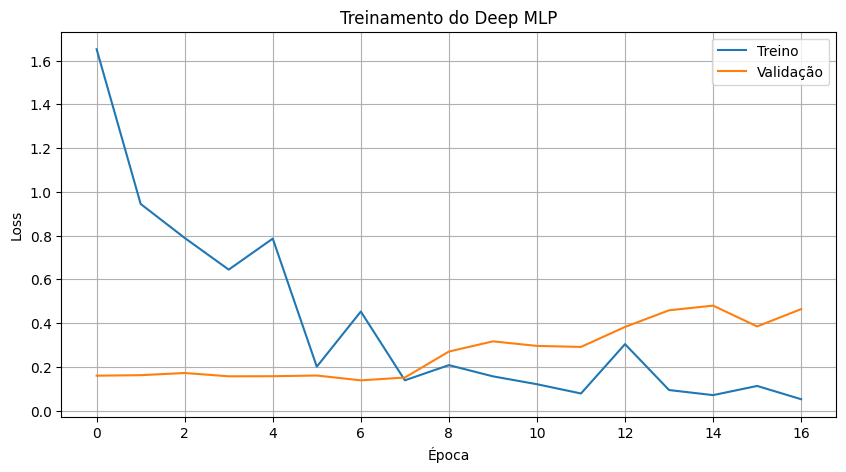

In [ ]:
# Gráfico de avaliação do treinamento

plt.figure(figsize=(10, 5))

plt.plot(history_mlp.history['loss'], label='Treino')
plt.plot(history_mlp.history['val_loss'], label='Validação')

plt.xlabel('Época')
plt.ylabel('Loss')
plt.title('Treinamento do Deep MLP')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Predição com os dados de teste

y_proba = model_mlp.predict(X_test_scaled).ravel()
y_pred = (y_proba >= 0.5).astype(int)

109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [ ]:
print(confusion_matrix(y_test, y_pred))

print(classification_report(y_test, y_pred, zero_division=0))

[[3367    0]
 [ 103    0]]
              precision    recall  f1-score   support

           0       0.97      1.00      0.98      3367
           1       0.00      0.00      0.00       103

    accuracy                           0.97      3470
   macro avg       0.49      0.50      0.49      3470
weighted avg       0.94      0.97      0.96      3470



### Testando arquitetura 4

In [ ]:
# Definindo o modelo

n_features = X_train_scaled.shape[1]

input_layer = layers.Input(shape=(n_features,))

x = layers.Dense(64, activation='relu')(input_layer)
x = layers.Dropout(0.3)(x)

x = layers.Dense(32, activation='relu')(x)
x = layers.Dropout(0.3)(x)

x = layers.Dense(16, activation='relu')(x)

output_layer = layers.Dense(1, activation='sigmoid')(x)

model_mlp = Model(inputs=input_layer, outputs=output_layer)

model_mlp.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall')
    ]
)

In [ ]:
# Treinando o modelo

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history_mlp = model_mlp.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    shuffle=False,
    class_weight=class_weights_dict,
    callbacks=[early_stop],
    verbose=0
)

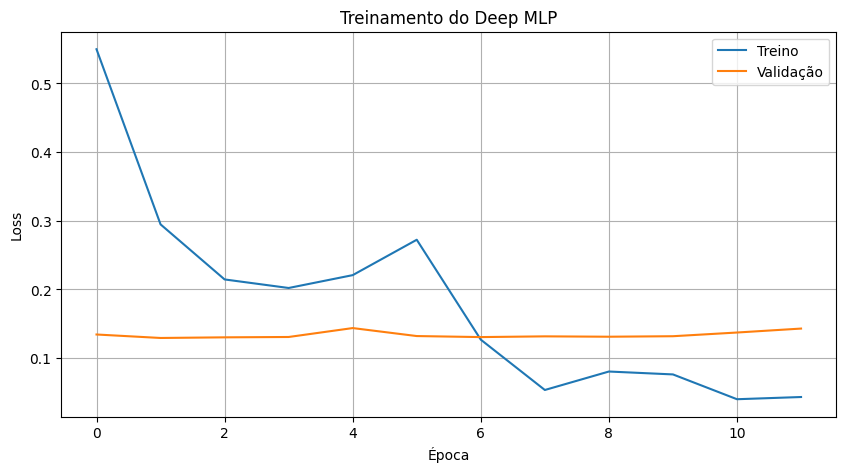

In [ ]:
# Gráfico de avaliação do treinamento

plt.figure(figsize=(10, 5))

plt.plot(history_mlp.history['loss'], label='Treino')
plt.plot(history_mlp.history['val_loss'], label='Validação')

plt.xlabel('Época')
plt.ylabel('Loss')
plt.title('Treinamento do Deep MLP')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Predição com os dados de teste

y_proba = model_mlp.predict(X_test_scaled).ravel()
y_pred = (y_proba >= 0.5).astype(int)

109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [ ]:
print(confusion_matrix(y_test, y_pred))

print(classification_report(y_test, y_pred, zero_division=0))

[[3367    0]
 [ 103    0]]
              precision    recall  f1-score   support

           0       0.97      1.00      0.98      3367
           1       0.00      0.00      0.00       103

    accuracy                           0.97      3470
   macro avg       0.49      0.50      0.49      3470
weighted avg       0.94      0.97      0.96      3470



## Nova etapa de feature engineering

In [ ]:
ds_bruto = pd.read_csv('transformers.csv')
ds_bruto.shape

(17348, 9)

In [ ]:
# Preparando o dataset

ds_classif_feat = ds_bruto.copy()

ds_classif_feat['date'] = pd.to_datetime(ds_classif_feat['date'])
ds_classif_feat = ds_classif_feat.sort_values('date').reset_index(drop=True)

In [ ]:
features_base = ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
janelas = [3, 6, 12, 24]

novas_colunas = {}

In [ ]:
for col in features_base:
    serie_passada = ds_classif_feat[col].shift(1)

    for w in janelas:
        novas_colunas[f'{col}_media_{w}h'] = serie_passada.rolling(w).mean()
        novas_colunas[f'{col}_std_{w}h'] = serie_passada.rolling(w).std()
        novas_colunas[f'{col}_max_{w}h'] = serie_passada.rolling(w).max()
        novas_colunas[f'{col}_min_{w}h'] = serie_passada.rolling(w).min()

    novas_colunas[f'{col}_diff_1h'] = ds_classif_feat[col].diff().shift(1)

In [ ]:
df_novas_colunas = pd.DataFrame(novas_colunas, index=ds_classif_feat.index)

ds_classif_feat = pd.concat([ds_classif_feat, df_novas_colunas], axis=1)

ds_classif_feat = ds_classif_feat.dropna().reset_index(drop=True)

In [ ]:
ds_classif_feat.shape

(17324, 128)

In [ ]:
# Separando a base de dados e rótulos

X = ds_classif_feat.drop(columns=['date', 'class'])
y = ds_classif_feat['class']

In [ ]:
# Split

idx_split = int(len(ds_classif_feat) * 0.8)

X_train = X.iloc[:idx_split].copy()
X_test = X.iloc[idx_split:].copy()

y_train = y.iloc[:idx_split].copy()
y_test = y.iloc[idx_split:].copy()

In [ ]:
# Padronização dos dados

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
# Class weight

classes = np.unique(y_train)

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)

class_weights_dict = dict(zip(classes, class_weights))

class_weights_dict

{np.int64(0): np.float64(0.5025382551309014),
 np.int64(1): np.float64(98.99285714285715)}

In [ ]:
# Definindo o modelo

n_features = X_train_scaled.shape[1]

input_layer = layers.Input(shape=(n_features,))

x = layers.Dense(64, activation='relu')(input_layer)
x = layers.Dropout(0.3)(x)

x = layers.Dense(32, activation='relu')(x)
x = layers.Dropout(0.3)(x)

x = layers.Dense(16, activation='relu')(x)

output_layer = layers.Dense(1, activation='sigmoid')(x)

model_mlp = Model(inputs=input_layer, outputs=output_layer)

model_mlp.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall')
    ]
)

In [ ]:
# Treinando o modelo

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history_mlp = model_mlp.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    shuffle=False,
    class_weight=class_weights_dict,
    callbacks=[early_stop],
    verbose=0
)

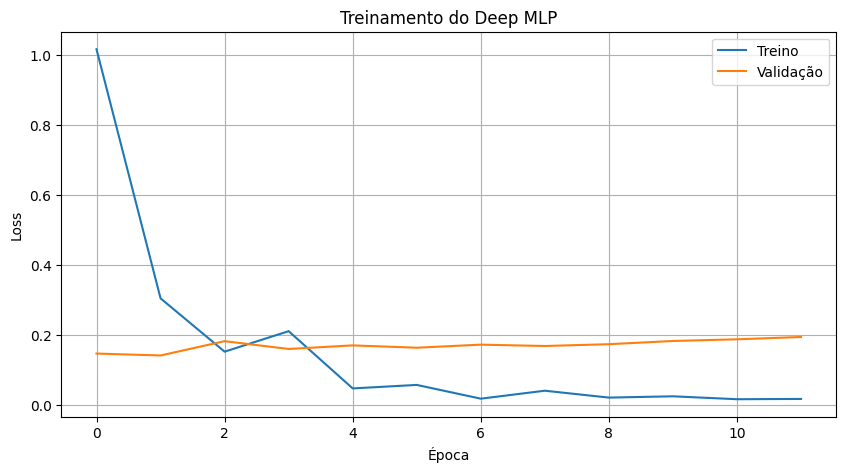

In [ ]:
# Gráfico de avaliação do treinamento

plt.figure(figsize=(10, 5))

plt.plot(history_mlp.history['loss'], label='Treino')
plt.plot(history_mlp.history['val_loss'], label='Validação')

plt.xlabel('Época')
plt.ylabel('Loss')
plt.title('Treinamento do Deep MLP')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Predição com os dados de teste

y_proba = model_mlp.predict(X_test_scaled).ravel()
y_pred = (y_proba >= 0.5).astype(int)

109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step


In [ ]:
print(confusion_matrix(y_test, y_pred))

print(classification_report(y_test, y_pred, zero_division=0))

[[3362    0]
 [ 103    0]]
              precision    recall  f1-score   support

           0       0.97      1.00      0.98      3362
           1       0.00      0.00      0.00       103

    accuracy                           0.97      3465
   macro avg       0.49      0.50      0.49      3465
weighted avg       0.94      0.97      0.96      3465



In [ ]:
# Predição com os dados de teste: threshold = 0.1

y_proba = model_mlp.predict(X_test_scaled).ravel()
y_pred = (y_proba >= 0.1).astype(int)

109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [ ]:
print(confusion_matrix(y_test, y_pred))

print(classification_report(y_test, y_pred, zero_division=0))

[[3168  194]
 [  97    6]]
              precision    recall  f1-score   support

           0       0.97      0.94      0.96      3362
           1       0.03      0.06      0.04       103

    accuracy                           0.92      3465
   macro avg       0.50      0.50      0.50      3465
weighted avg       0.94      0.92      0.93      3465

